In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [5]:
# load the csv
df = pd.read_csv("data/battery_data.csv")

arr = df.to_numpy()
hours_arr = arr[:,0].astype(float)
life_arr = arr[:,1].astype(float)

<function matplotlib.pyplot.show(close=None, block=None)>

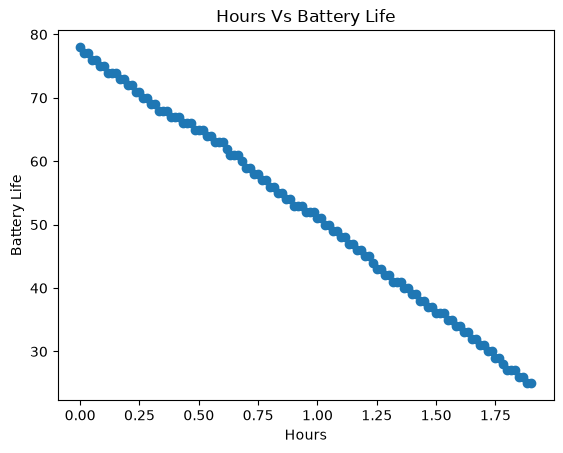

In [6]:
plt.scatter(hours_arr, life_arr)
plt.title("Hours Vs Battery Life")
plt.xlabel("Hours")
plt.ylabel("Battery Life")
plt.show

In [7]:
# cost calculation

def cost(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> float:    
    f_wb = w * x_i + b
    sum = (f_wb - y_i) ** 2
    sum = np.sum(sum)
    cost = sum / (2 * len(x_i))
    return cost

In [8]:
def gradient(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> tuple:
    f_wb = w * x_i + b
    sum_b = f_wb - y_i
    sum_w = sum_b * x_i
    sum_w = np.sum(sum_w)
    sum_b = np.sum(sum_b)

    grad_w = sum_w / (len(x_i))
    grad_b = sum_b / (len(x_i))
    return grad_w, grad_b

In [9]:
# change w and b simultaneously until we done

def lin_regression(x_i: np.ndarray, y_i: np.ndarray, alpha: float, cost, gradient) -> tuple:
    costs = []
    parameters = []
    w = 0
    b = 0
    prev_cost = 0
    curr_cost = cost(x_i, y_i, w, b)
    iters = 0
    while (abs(prev_cost - curr_cost) > 0.0000001):
        prev_cost = curr_cost
        grad_w, grad_b = gradient(x_i, y_i, w, b)
        w = w - alpha * grad_w
        b = b - alpha * grad_b
        curr_cost = cost(x_i, y_i, w, b)
        costs.append(curr_cost)
        parameters.append([w, b])
        if iters % 50 == 0:
            print(f"iter: {iters} w: {w} b: {b} cost: {curr_cost}")
        iters += 1            
    return w, b, costs, parameters

In [10]:
w_final, b_final, costs, parameters = lin_regression(hours_arr, life_arr, 0.1, cost, gradient)
print(w_final, b_final)

iter: 0 w: 4.073964699667721 b: 5.185217391304349 cost: 1071.7881536070847
iter: 50 w: -3.9234499632587254 b: 51.614230954941384 cost: 95.54413427195001
iter: 100 w: -16.52412112081863 b: 65.67489930678347 cost: 21.50529634868648
iter: 150 w: -22.484850247443433 b: 72.32610427324676 cost: 4.93774098270071
iter: 200 w: -25.304523635036862 b: 75.47240151823627 cost: 1.2304449373623332
iter: 250 w: -26.638346702890498 b: 76.96073128797354 cost: 0.4008690787538453
iter: 300 w: -27.269300622648153 b: 77.66477331928951 cost: 0.21523618168554856
iter: 350 w: -27.56776813190947 b: 77.99781455244779 cost: 0.17369739759921937
iter: 400 w: -27.708955707253928 b: 78.15535694061501 cost: 0.1644023286183366
iter: 450 w: -27.775743316669004 b: 78.22988105834675 cost: 0.1623223855179377
iter: 500 w: -27.807336640376857 b: 78.2651340730326 cost: 0.16185695989174842
iter: 550 w: -27.82228159965373 b: 78.28181021871889 cost: 0.161752812324696
iter: 600 w: -27.829351188464752 b: 78.28969873087681 cost: 0.

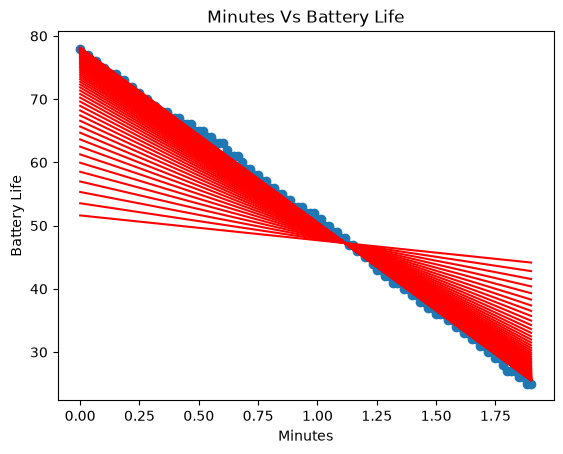

In [11]:
plt.scatter(hours_arr, life_arr)
for i in range(50, 400, 5):
    plt.plot(hours_arr, parameters[i][0]*hours_arr + parameters[i][1], color="red", label="model")
plt.title("Minutes Vs Battery Life")
plt.xlabel("Minutes")
plt.ylabel("Battery Life")
plt.show()